# Parte 0 — O piso

**Objetivo:** estabelecer um piso experimental treinando apenas com `rotulos_5.csv` (105 imagens) e comparar **(a) uma CNN pequena treinada do zero** com **(b) uma ResNet-18 pré-treinada no ImageNet com fine-tuning**. Os conjuntos de validação e `test_public` são usados para seleção de checkpoint e avaliação, respectivamente, não para treinamento.

In [5]:
from torch.utils.data import DataLoader
import pandas as pd
%load_ext autoreload
%autoreload 2
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay
import torch
import torch.nn as nn
import numpy as np
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
# Importando a classe do seu arquivo dentro de src
from src.redimensionamento import DatasetTrap, train_epoch, transform_treino, transform_val, eval_model, CNN_pequena

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Reprodutibilidade

In [6]:
import random
torch.manual_seed(0); np.random.seed(0); random.seed(0)


## Dados

Leitura dos rótulos de treino, validação e teste público; codificação consistente das classes com `LabelEncoder` ajustado somente no treino.

In [7]:
df_treino = pd.read_csv("pa3_dados/labels/rotulos_5.csv")
df_val = pd.read_csv("pa3_dados/labels/val.csv")
df_teste = pd.read_csv('pa3_dados/labels/test_public.csv')
le = LabelEncoder()
df_treino['label'] = le.fit_transform(df_treino['label'])
df_val['label'] = le.transform(df_val['label'])
df_teste['label'] = le.transform(df_teste['label'])



In [8]:
dataset_treino = DatasetTrap(df=df_treino, raiz="pa3_dados/images/train", augment=transform_treino)
dataset_val = DatasetTrap(df=df_val, raiz="pa3_dados/images/val", augment=transform_val)
dataset_teste = DatasetTrap(df=df_teste, raiz = "pa3_dados/images/test_public", augment= transform_val  )

loader_val = DataLoader(dataset_val, batch_size=16, shuffle= False)
loader_train = DataLoader(dataset_treino, batch_size=16, shuffle= True)
loader_test = DataLoader(dataset_teste, batch_size= 16, shuffle= False)

In [9]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'xpu' if hasattr(torch, 'xpu') and torch.xpu.is_available() else 'cpu')

In [ ]:
# Pesos de classe calculados somente a partir dos 105 exemplos de treino
rotulos_treino = df_treino['label'].values
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(rotulos_treino),
    y=rotulos_treino,
)
pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE)

## (b) ResNet-18 pré-treinada com fine-tuning

In [11]:
modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
num_entradas = modelo.fc.in_features
modelo.fc = nn.Linear(num_entradas, len(le.classes_))
modelo = modelo.to(DEVICE)
criterio = nn.CrossEntropyLoss(weight=pesos_tensor)

In [12]:
history = train_epoch(model=modelo, device=DEVICE, criterio=criterio, train_loader=loader_train, val_loader=loader_val, label="resnet18_parte0")

Epoch 1/10 | F1: 0.1029 | Train Loss: 3.088340250651042 | Val Loss: 2.855580547068379 
Epoch 2/10 | F1: 0.2154 | Train Loss: 2.1644856770833334 | Val Loss: 2.602264102142636 
Epoch 3/10 | F1: 0.3188 | Train Loss: 1.509534418015253 | Val Loss: 2.3993142005240564 
Epoch 4/10 | F1: 0.3580 | Train Loss: 1.1772261846633185 | Val Loss: 2.2761410250522123 
Epoch 5/10 | F1: 0.3587 | Train Loss: 0.8436613537016369 | Val Loss: 2.225156576326578 
Epoch 6/10 | F1: 0.3511 | Train Loss: 0.7087625412713914 | Val Loss: 2.1631388144918007 
Epoch 7/10 | F1: 0.3770 | Train Loss: 0.5055074419294084 | Val Loss: 2.1039952948541925 
Epoch 8/10 | F1: 0.3766 | Train Loss: 0.44488263811383927 | Val Loss: 2.0950101342531715 
Epoch 9/10 | F1: 0.3951 | Train Loss: 0.33670182001023063 | Val Loss: 2.088931395275758 
Epoch 10/10 | F1: 0.3726 | Train Loss: 0.22399482727050782 | Val Loss: 2.091006590588258 


### Curva de treino e validação

A partir das curvas, observa-se indício de **sobreajuste por volta da época 7**, quando o modelo começa a decorar os exemplos de treino. A escolha do checkpoint é feita pela melhor F1 macro de validação, não pela última época.

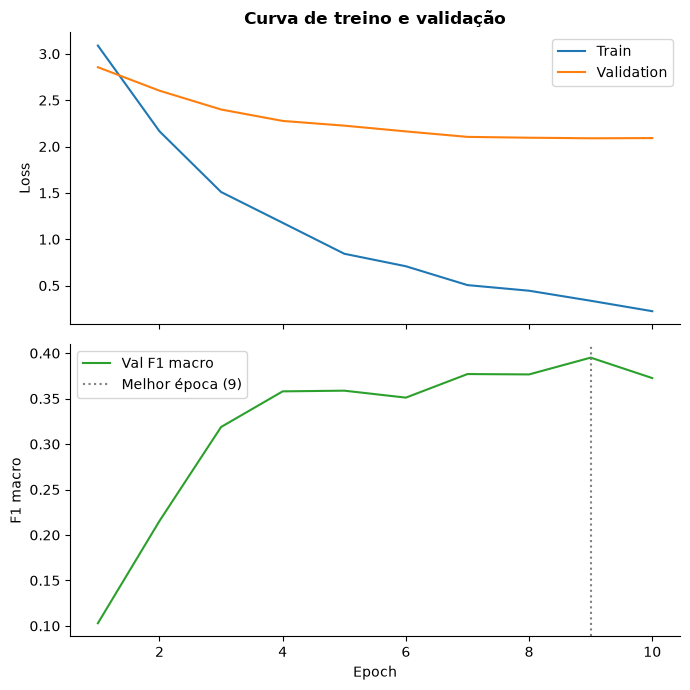

In [13]:
epocas = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Loss
ax1.plot(epocas, history['train_loss'], label='Train')
ax1.plot(epocas, history['val_loss'], label='Validation')
ax1.set_ylabel('Loss')
ax1.set_title('Curva de treino e validação', fontweight='bold')
ax1.legend()

# F1 de validação
ax2.plot(epocas, history['f1_score'], color='tab:green', label='Val F1 macro')
melhor = int(np.argmax(history['f1_score']))
ax2.axvline(melhor + 1, color='gray', linestyle=':', label=f'Melhor época ({melhor + 1})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 macro')
ax2.legend()

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Avaliação no test_public (checkpoint de melhor F1 no val)

In [14]:
# Recupera o checkpoint escolhido pela melhor F1 macro na validação
pesos_salvos = torch.load('models/best_model_resnet18_parte0.pt', map_location=DEVICE, weights_only=True)
modelo.load_state_dict(pesos_salvos)
previsoes_teste, rotulos_teste = eval_model(modelo, loader_test, criterio, DEVICE)
print('F1 macro (b):', f1_score(rotulos_teste, previsoes_teste, average='macro'))
print('Acurácia (b):', accuracy_score(rotulos_teste, previsoes_teste))

 F1: 0.4006 |  Teste Loss 1.960547507176711 
F1 macro (b): 0.4005815811569237
Acurácia (b): 0.4315659679408138


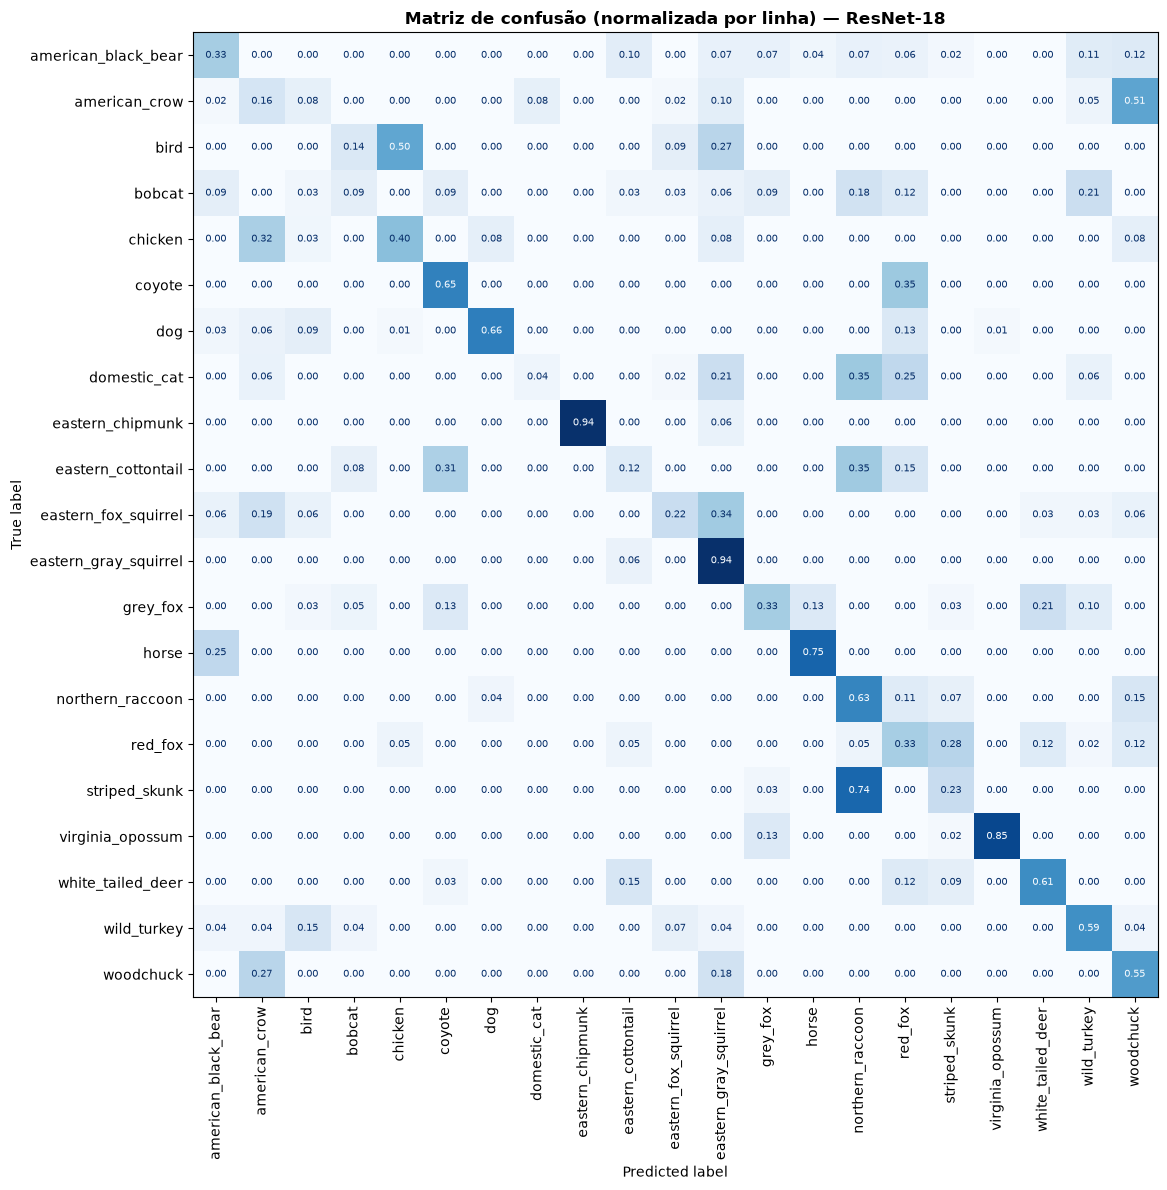

In [15]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    rotulos_teste, previsoes_teste,
    labels=range(len(le.classes_)),
    display_labels=le.classes_,
    normalize='true',
    values_format='.2f',
    xticks_rotation=90,
    colorbar=False,
    cmap='Blues',
    ax=ax,
)
for t in ax.texts:
    t.set_fontsize(7)
ax.set_title('Matriz de confusão (normalizada por linha) — ResNet-18', fontweight='bold')
plt.tight_layout()
plt.show()

## (a) CNN pequena do zero

In [16]:
modelo_CNN = CNN_pequena().to(DEVICE)
criterio_cnn = nn.CrossEntropyLoss(weight=pesos_tensor)

history_opcao_a = train_epoch(
    model=modelo_CNN,
    device=DEVICE,
    criterio=criterio_cnn,
    train_loader=loader_train,
    val_loader=loader_val,
    label="cnn_parte0",
    epochs=60,      # suba para 100 se a val ainda estiver melhorando
    lr=1e-3,
)
modelo_CNN.load_state_dict(torch.load('models/best_model_cnn_parte0.pt', map_location=DEVICE, weights_only=True))


previsoes_a, rotulos_a = eval_model(modelo_CNN, loader_test, criterio_cnn, DEVICE)
print("F1 macro:", f1_score(rotulos_a, previsoes_a, average='macro'))
print("Acurácia:", accuracy_score(rotulos_a, previsoes_a))

Epoch 1/60 | F1: 0.0355 | Train Loss: 3.3798081170944942 | Val Loss: 3.049015158473855 
Epoch 2/60 | F1: 0.0669 | Train Loss: 3.0371041434151786 | Val Loss: 2.9885398940284653 
Epoch 3/60 | F1: 0.0795 | Train Loss: 2.769399879092262 | Val Loss: 3.08269206132039 
Epoch 4/60 | F1: 0.0996 | Train Loss: 2.5835536411830358 | Val Loss: 3.2121440018757736 
Epoch 5/60 | F1: 0.1380 | Train Loss: 2.223803129650298 | Val Loss: 3.344722030186417 
Epoch 6/60 | F1: 0.2008 | Train Loss: 1.8392737978980656 | Val Loss: 3.905291264600093 
Epoch 7/60 | F1: 0.1790 | Train Loss: 1.6604910714285714 | Val Loss: 4.508037000599474 
Epoch 8/60 | F1: 0.1865 | Train Loss: 1.6176680791945683 | Val Loss: 4.272756142191367 
Epoch 9/60 | F1: 0.1736 | Train Loss: 1.447527349562872 | Val Loss: 3.8859549040841586 
Epoch 10/60 | F1: 0.2227 | Train Loss: 1.1316487630208334 | Val Loss: 4.069870448348546 
Epoch 11/60 | F1: 0.2149 | Train Loss: 1.01233396984282 | Val Loss: 4.519956078859839 
Epoch 12/60 | F1: 0.1825 | Train 

## Resumo do piso

Comparação dos dois modelos no mesmo conjunto `test_public`, usando F1 macro e acurácia.

In [17]:
resumo = pd.DataFrame({
    'modelo': ['CNN do zero (a)', 'ResNet-18 ImageNet (b)'],
    'f1_macro': [f1_score(rotulos_a, previsoes_a, average='macro'),
                 f1_score(rotulos_teste, previsoes_teste, average='macro')],
    'acuracia': [accuracy_score(rotulos_a, previsoes_a),
                 accuracy_score(rotulos_teste, previsoes_teste)],
})
resumo

,modelo,f1_macro,acuracia
0,CNN do zero (a),0.313180,0.353884
1,ResNet-18 ImageNet (b),0.400582,0.431566


## Parte 2

In [ ]:
orcamentos = [1, 5, 20]

for orc in orcamentos:
    if orc in [1, 20]:
        lista = [42]
    elif orc ==5:
        lista = [42, 7, 99] 
    for seed in lista:

        df = pd.read_csv(f'pa3_dados/labels/rotulos_{orc}.csv')
        np.random.seed(seed)

        # PyTorch (CPU e GPU)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) 
        df['label'] = le.transform(df['label'])
        dataset_treino = DatasetTrap(df=df, raiz="pa3_dados/images/train", augment=transform_treino)
        loader_train = DataLoader(dataset_treino, batch_size=16, shuffle= True)

        modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        modelo.fc = nn.Linear(num_entradas, len(le.classes_))
        pesos = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(df['label']),
            y=df['label'])
        pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE))
        criterio = nn.CrossEntropyLoss(weight=pesos_tensor)
        modelo.to(DEVICE)
        
        

SyntaxError: unmatched ')' (2134393319.py, line 27)